# 02 · Preguntas de negocio

En este notebook respondemos, paso a paso, las 5 preguntas del proyecto:

1. ¿Cómo evolucionan las ventas por año y mes? ¿Hay estacionalidad?
2. ¿Qué familias de producto venden más y cuáles crecen o caen?
3. ¿Qué tiendas y ciudades rinden mejor?
4. ¿Las promociones aumentan las ventas?
5. ¿Los feriados, el petróleo y el terremoto de 2016 afectaron las ventas?

Usamos las tablas limpias que creamos en `01_exploracion_y_limpieza.ipynb` (ejecútalo primero).
Cada gráfico se guarda en la carpeta `images/` para usarlo en el README.

> **Recordatorio:** `ventas` son **unidades vendidas**, no dólares.

## Paso 0 · Preparación: librerías, estilo de gráficos y datos

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)

# --- Estilo común para todos los gráficos ---
AZUL = "#2a78d6"      # color principal
ROJO = "#e34948"      # para caídas / valores negativos
GRIS = "#898781"      # elementos secundarios
TINTA = "#0b0b0b"
TINTA_2 = "#52514e"
CUADRICULA = "#e1e0d9"
FONDO = "#fcfcfb"

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CUADRICULA, "grid.linewidth": 0.6,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "lines.linewidth": 2,
})

def en_millones(x, _):
    return f"{x / 1e6:,.1f} M"

def en_miles(x, _):
    return f"{x / 1e3:,.0f} mil"

def guardar(fig, nombre):
    fig.savefig(IMAGES / f"{nombre}.png", dpi=150, bbox_inches="tight", facecolor=FONDO)

In [2]:
diaria = pd.read_csv(PROCESSED / "ventas_diarias.csv", parse_dates=["date"])
mensual = pd.read_csv(PROCESSED / "ventas_mensuales_tienda_familia.csv", parse_dates=["mes"])

diaria["anio"] = diaria["date"].dt.year
diaria["mes"] = diaria["date"].dt.month
diaria["dia_semana"] = diaria["date"].dt.day_of_week   # 0 = lunes ... 6 = domingo
diaria["dia_mes"] = diaria["date"].dt.day

# Decisiones de calidad tomadas en el notebook 01
PERIODO_CONFIABLE = "2015-06-01"
calidad = pd.read_csv(PROCESSED / "calidad_familias.csv", index_col="family")
familias_completas = calidad[~calidad["con_huecos"]].index.tolist()
diaria.head()

,date,ventas,productos_en_promo,ventas_familias_completas,transacciones,precio_petroleo,tipo_dia,descripcion_feriado,anio,mes,dia_semana,dia_mes
0,2013-01-01,"2,511.62",0,"1,701.62",770.00,93.14,Feriado,Primer dia del ano,2013,1,1,1
1,2013-01-02,"496,092.42",0,"424,000.42","93,215.00",93.14,Dia normal,NaN,2013,1,2,2
2,2013-01-03,"361,461.23",0,"309,356.23","78,504.00",92.97,Dia normal,NaN,2013,1,3,3
3,2013-01-04,"354,459.68",0,"300,292.68","78,494.00",93.12,Dia normal,NaN,2013,1,4,4
4,2013-01-05,"477,350.12",0,"399,532.12","93,573.00",93.12,Dia normal,Recupero puente Navidad,2013,1,5,5


---
# Pregunta 1 · ¿Cómo evolucionan las ventas por año y mes? ¿Hay estacionalidad?

### Paso 1.1 · Ventas por año

⚠️ **Dos trampas** que ya conocemos del notebook 01:

1. **2017 solo llega al 15 de agosto.** Si sumamos por año, 2017 parecerá peor solo por tener menos días.
   → Comparamos el **mismo periodo** en todos los años (1 de enero a 15 de agosto).
2. **Huecos de registro hasta mayo de 2015.** → Para comparar años usamos solo las **familias completas**
   (las 20 familias que se registraron bien todo el tiempo). También mostramos el total para ver la diferencia.

In [3]:
mismo_periodo = diaria[diaria["date"].dt.strftime("%m-%d") <= "08-15"]
por_anio = mismo_periodo.groupby("anio")[["ventas", "ventas_familias_completas"]].sum()
por_anio["crec_total_%"] = por_anio["ventas"].pct_change() * 100
por_anio["crec_familias_completas_%"] = por_anio["ventas_familias_completas"].pct_change() * 100
por_anio

,ventas,ventas_familias_completas,crec_total_%,crec_familias_completas_%
anio,,,,
2013,"82,710,648.40","69,741,583.40",NaN,NaN
2014,"116,991,274.69","83,522,180.60",41.45,19.76
2015,"132,169,528.08","96,344,562.51",12.97,15.35
2016,"176,562,909.57","106,574,369.16",33.59,10.62
2017,"194,217,068.37","115,686,801.49",10.00,8.55


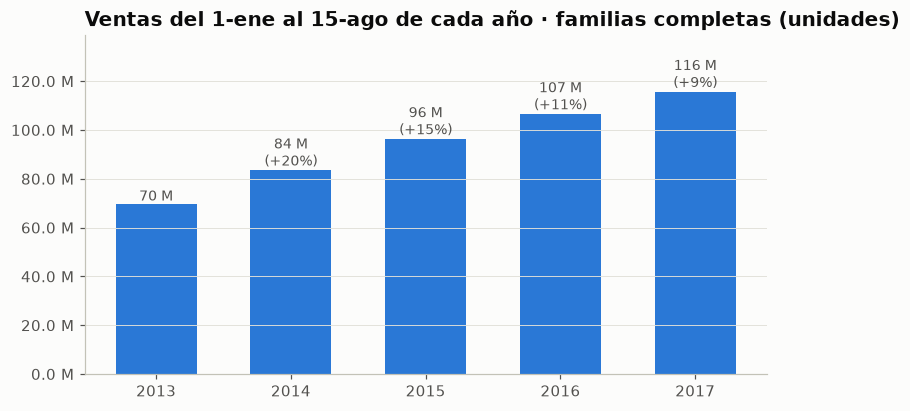

In [4]:
serie = por_anio["ventas_familias_completas"]
crec = por_anio["crec_familias_completas_%"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(serie.index.astype(str), serie, color=AZUL, width=0.6)
for x, (v, c) in enumerate(zip(serie, crec)):
    texto = f"{v/1e6:,.0f} M" + ("" if pd.isna(c) else f"\n({c:+.0f}%)")
    ax.text(x, v, texto, ha="center", va="bottom", fontsize=9, color=TINTA_2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(en_millones))
ax.set_title("Ventas del 1-ene al 15-ago de cada año · familias completas (unidades)")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, serie.max() * 1.2)
guardar(fig, "p1_ventas_por_anio")
plt.show()

**¿Qué vemos?** Con datos comparables, las ventas crecen **todos los años**, pero cada vez más despacio:
+20% (2014), +15% (2015), +11% (2016) y +9% (2017). El total "ingenuo" (todas las familias) habría mostrado
un +41% en 2014 y un +34% en 2016, inflados por los huecos de registro. Parte del crecimiento viene también de las
tiendas nuevas que abrieron entre 2013 y 2015.

### Paso 1.2 · Evolución mes a mes

Usamos el **promedio diario** de cada mes (para que meses de 28 y 31 días sean comparables) y dibujamos las dos
series: el total y las familias completas. La zona gris marca el periodo con huecos de registro.

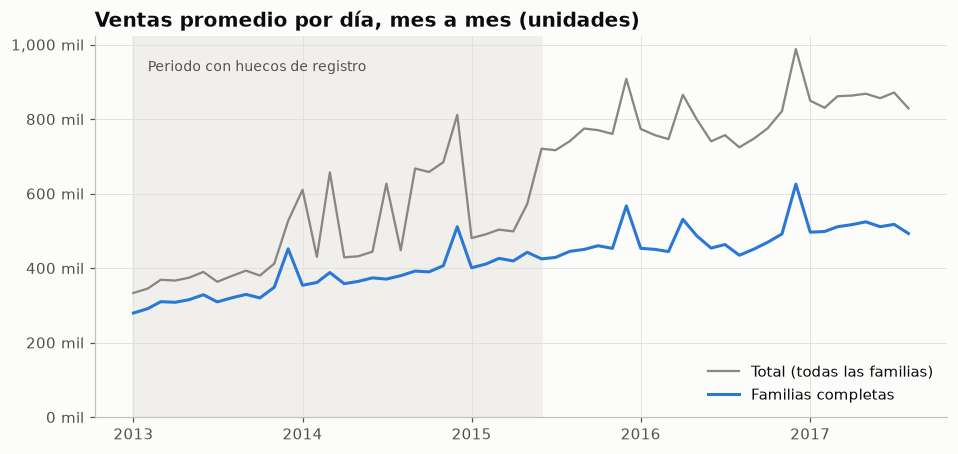

In [5]:
por_mes = diaria.set_index("date")[["ventas", "ventas_familias_completas"]].resample("MS").mean()

fig, ax = plt.subplots()
ax.axvspan(por_mes.index.min(), pd.Timestamp(PERIODO_CONFIABLE), color="#f0efec", zorder=0)
ax.text(pd.Timestamp("2013-02-01"), por_mes["ventas"].max() * 0.97, "Periodo con huecos de registro",
        fontsize=9, color=TINTA_2, va="top")
ax.plot(por_mes.index, por_mes["ventas"], color=GRIS, linewidth=1.5, label="Total (todas las familias)")
ax.plot(por_mes.index, por_mes["ventas_familias_completas"], color=AZUL, label="Familias completas")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(en_miles))
ax.set_title("Ventas promedio por día, mes a mes (unidades)")
ax.set_ylim(0)
ax.legend(loc="lower right", frameon=False)
guardar(fig, "p1_ventas_mensuales")
plt.show()

**¿Qué vemos?** La línea gris (total) salta arriba y abajo hasta mayo de 2015 por los huecos; la línea azul
(familias completas) es estable y muestra una **tendencia creciente** con un **pico cada diciembre**.

### Paso 1.3 · Mapa de calor año × mes

Un mapa de calor (*heatmap*) muestra la estacionalidad de un vistazo: cada fila es un año y cada columna un mes.
Como las ventas crecen cada año, comparamos cada mes **con el promedio de su propio año** (100 = mes promedio).
Usamos las familias completas.

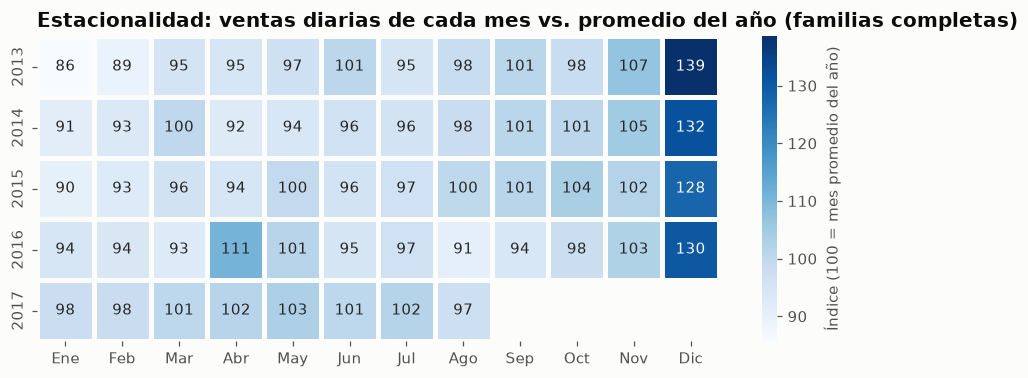

In [6]:
tabla = diaria.groupby(["anio", "mes"])["ventas_familias_completas"].mean().unstack()
indice = tabla.div(tabla.mean(axis=1), axis=0) * 100   # cada año: 100 = mes promedio

nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(indice, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Índice (100 = mes promedio del año)"},
            xticklabels=nombres_mes, linewidths=2, linecolor=FONDO, ax=ax)
ax.set_title("Estacionalidad: ventas diarias de cada mes vs. promedio del año (familias completas)")
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
guardar(fig, "p1_heatmap_estacionalidad")
plt.show()

**¿Qué vemos?**

- **Diciembre** es el mejor mes todos los años, con diferencia.
- Los primeros meses del año (enero–febrero) suelen estar por debajo del promedio.
- El índice de 2017 se ve distinto porque solo tiene enero–agosto (no hay diciembre).

### Paso 1.4 · Estacionalidad semanal y por día del mes

Aquí usamos todas las familias, pero solo el **periodo confiable** (desde junio de 2015).

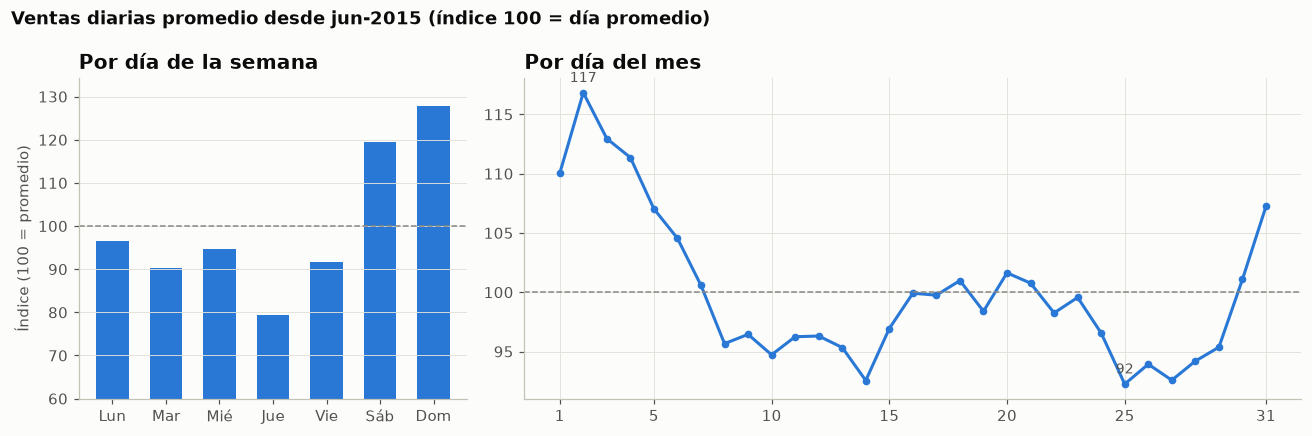

{'Lun': 96.0, 'Mar': 90.0, 'Mié': 95.0, 'Jue': 79.0, 'Vie': 92.0, 'Sáb': 120.0, 'Dom': 128.0}


In [7]:
confiable = diaria[diaria["date"] >= PERIODO_CONFIABLE]

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia_semana = confiable.groupby("dia_semana")["ventas"].mean()
por_dia_semana = por_dia_semana / por_dia_semana.mean() * 100

por_dia_mes = confiable.groupby("dia_mes")["ventas"].mean()
por_dia_mes = por_dia_mes / por_dia_mes.mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})
ax1.bar(dias, por_dia_semana, color=AZUL, width=0.6)
ax1.axhline(100, color=GRIS, linewidth=1, linestyle="--")
ax1.set_title("Por día de la semana")
ax1.set_ylabel("Índice (100 = promedio)")
ax1.grid(axis="x", visible=False)
ax1.set_ylim(60)

ax2.plot(por_dia_mes.index, por_dia_mes.values, color=AZUL, marker="o", markersize=4)
ax2.axhline(100, color=GRIS, linewidth=1, linestyle="--")
ax2.set_title("Por día del mes")
ax2.set_xticks([1, 5, 10, 15, 20, 25, 31])
for d in [por_dia_mes.idxmax(), por_dia_mes.idxmin()]:
    ax2.annotate(f"{por_dia_mes[d]:.0f}", (d, por_dia_mes[d]), textcoords="offset points",
                 xytext=(0, 7), ha="center", fontsize=9, color=TINTA_2)
fig.suptitle("Ventas diarias promedio desde jun-2015 (índice 100 = día promedio)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "p1_dia_semana_y_dia_mes")
plt.show()
print(por_dia_semana.round(0).set_axis(dias).to_dict())

**¿Qué vemos?**

- **Sábado y domingo** son los días con más ventas; entre semana, el **jueves** es el más bajo.
- Las ventas suben **a fin y a inicio de mes**, y hay un pequeño repunte alrededor del 15. Coincide con los días
  de pago de sueldos (en Ecuador el sector público paga los días 15 y a fin de mes).

### ✅ Respuesta a la pregunta 1

Con datos comparables, las ventas **crecen todos los años** a un ritmo moderado y tienen **estacionalidad clara** en
tres niveles: **anual** (diciembre ~30% sobre el promedio; enero y febrero los meses más flojos), **semanal** (fines de semana altos) y
**mensual** (más ventas en los días de pago).

---
# Pregunta 2 · ¿Qué familias de producto venden más y cuáles crecen o caen?

### Paso 2.1 · Ranking de familias

Usamos el **periodo confiable** (desde junio de 2015), porque antes varias familias grandes estaban incompletas
y su peso saldría subestimado.

In [8]:
mensual["anio"] = mensual["mes"].dt.year
mensual_conf = mensual[mensual["mes"] >= PERIODO_CONFIABLE]

por_familia = mensual_conf.groupby("family")["ventas"].sum().sort_values(ascending=False)
participacion = por_familia / por_familia.sum() * 100

resumen_familias = pd.DataFrame({"ventas": por_familia, "participacion_%": participacion,
                                 "acumulado_%": participacion.cumsum()})
resumen_familias.head(10)

,ventas,participacion_%,acumulado_%
family,,,
GROCERY I,"190,294,663.51",29.42,29.42
BEVERAGES,"141,397,860.00",21.86,51.28
PRODUCE,"99,079,650.89",15.32,66.60
CLEANING,"51,332,997.00",7.94,74.53
DAIRY,"37,392,424.00",5.78,80.31
BREAD/BAKERY,"22,876,338.30",3.54,83.85
POULTRY,"16,905,766.19",2.61,86.46
MEATS,"15,539,348.10",2.40,88.87
PERSONAL CARE,"13,623,607.00",2.11,90.97


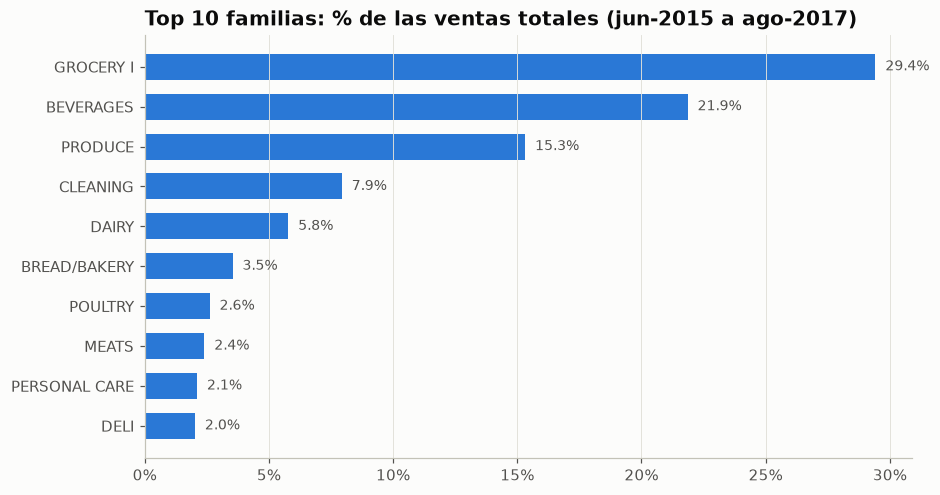

In [9]:
top = participacion.head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values, color=AZUL, height=0.65)
for y, v in enumerate(top.values):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", fontsize=9, color=TINTA_2)
ax.set_title("Top 10 familias: % de las ventas totales (jun-2015 a ago-2017)")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
guardar(fig, "p2_top_familias")
plt.show()

**¿Qué vemos?** Las ventas están **muy concentradas** en pocas familias: abarrotes (`GROCERY I`), bebidas
(`BEVERAGES`) y frutas y verduras (`PRODUCE`) suman cerca de dos tercios del total.

### Paso 2.2 · ¿Qué familias crecen o caen?

Para que la comparación sea justa:

- Comparamos los **últimos 12 meses** (16-ago-2016 a 15-ago-2017) contra los **12 meses anteriores**
  (16-ago-2015 a 15-ago-2016). Ambos periodos están dentro del periodo confiable y tienen un año completo de
  estacionalidad (cada uno incluye un diciembre).
- Usamos solo las **tiendas que ya vendían en agosto de 2015** (así el crecimiento no se debe a tiendas nuevas).

Como necesitamos cortar el 15 de agosto, usamos los datos diarios de `train.csv`.

In [10]:
train = pd.read_csv(RAW / "train.csv", parse_dates=["date"],
                    usecols=["date", "store_nbr", "family", "sales", "onpromotion"])

tiendas_comparables = mensual[(mensual["mes"] == "2015-08-01") & (mensual["ventas"] > 0)]["store_nbr"].unique()
print("Tiendas comparables:", len(tiendas_comparables))

t = train[train["store_nbr"].isin(tiendas_comparables) & (train["date"] >= "2015-08-16")].copy()
t["periodo"] = (t["date"] >= "2016-08-16").map({False: "anterior", True: "ultimo_anio"})

crecimiento = t.pivot_table(index="family", columns="periodo", values="sales", aggfunc="sum")
crecimiento["cambio_%"] = (crecimiento["ultimo_anio"] / crecimiento["anterior"] - 1) * 100
crecimiento.sort_values("cambio_%")

Tiendas comparables: 52


periodo,anterior,ultimo_anio,cambio_%
family,,,
SEAFOOD,"465,121.81","436,751.65",-6.10
PREPARED FOODS,"2,091,194.72","1,975,561.45",-5.53
CELEBRATION,"284,772.00","269,387.00",-5.40
HOME AND KITCHEN II,"574,700.00","543,952.00",-5.35
FROZEN FOODS,"3,602,337.75","3,471,946.79",-3.62
AUTOMOTIVE,"138,189.00","135,921.00",-1.64
POULTRY,"7,628,310.49","7,559,335.19",-0.90
PERSONAL CARE,"6,107,447.00","6,197,261.00",1.47
LADIESWEAR,"225,492.00","229,220.00",1.65


Algunas familias pequeñas (`BOOKS`, `BABY CARE`) muestran cambios enormes porque venden muy poco: con números
tan chicos, el porcentaje no significa mucho. Para el gráfico nos quedamos con las familias que pesan al menos
**0,5% de las ventas**:

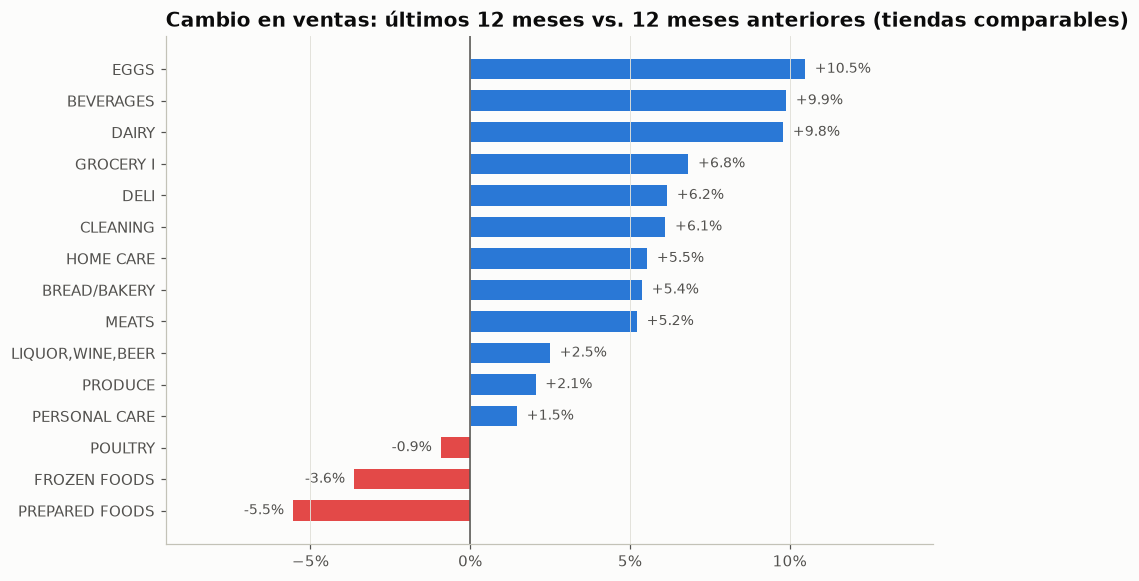

Crecimiento total en tiendas comparables: +6.3%


In [11]:
relevantes = participacion[participacion >= 0.5].index
graf = crecimiento.loc[crecimiento.index.isin(relevantes), "cambio_%"].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colores = [ROJO if v < 0 else AZUL for v in graf.values]
ax.barh(graf.index, graf.values, color=colores, height=0.65)
for y, v in enumerate(graf.values):
    ax.text(v + (0.3 if v >= 0 else -0.3), y, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_title("Cambio en ventas: últimos 12 meses vs. 12 meses anteriores (tiendas comparables)")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(min(graf.min(), 0) - 4, graf.max() + 4)
ax.grid(axis="y", visible=False)
guardar(fig, "p2_crecimiento_familias")
plt.show()

total_crec = crecimiento["ultimo_anio"].sum() / crecimiento["anterior"].sum() - 1
print(f"Crecimiento total en tiendas comparables: {total_crec:+.1%}")

### ✅ Respuesta a la pregunta 2

- **Las que más venden:** `GROCERY I` (29%), `BEVERAGES` (22%) y `PRODUCE` (15%) suman **dos tercios** de las
  ventas; con `CLEANING` y `DAIRY`, las 5 primeras llegan al **80%**.
- **Crecimiento general:** en tiendas comparables, las ventas del último año crecieron **+6,3%**.
- **Las que más crecen** (entre las relevantes): `EGGS` (+10,5%), `BEVERAGES` (+9,9%) y `DAIRY` (+9,8%).
  `GROCERY I`, la familia más grande, crece +6,8%.
- **Las que caen:** `PREPARED FOODS` (−5,5%), `FROZEN FOODS` (−3,6%) y `POULTRY` (−0,9%). Entre las familias
  pequeñas también caen `SEAFOOD`, `CELEBRATION` y `HOME AND KITCHEN II` (~−5%).

> 💡 **Lección:** si hubiéramos comparado 2014 con 2016 sin revisar la calidad de los datos, `PRODUCE` habría
> aparecido con un crecimiento de casi +90%. Con datos comparables, su crecimiento real es de solo **+2%**:
> aquel "crecimiento" era un efecto de los huecos de registro.

---
# Pregunta 3 · ¿Qué tiendas y ciudades rinden mejor?

### Paso 3.1 · Elegir una métrica justa

Usamos las **ventas promedio por día** desde el **1 de enero de 2016**. Para entonces todas las tiendas, menos la
52, ya estaban abiertas; para la 52 dividimos solo por los días en que estuvo abierta.

In [12]:
desde_2016 = mensual[mensual["mes"] >= "2016-01-01"]
dias_abierta = (pd.read_csv(RAW / "transactions.csv", parse_dates=["date"])
                .query("date >= '2016-01-01'")
                .groupby("store_nbr")["date"].nunique()
                .rename("dias_abierta"))

tiendas = (desde_2016.groupby(["store_nbr", "city", "state", "type", "cluster"])["ventas"].sum()
           .reset_index()
           .merge(dias_abierta, on="store_nbr"))
tiendas["ventas_por_dia"] = tiendas["ventas"] / tiendas["dias_abierta"]
tiendas = tiendas.sort_values("ventas_por_dia", ascending=False)
tiendas.head(10)

,store_nbr,city,state,type,cluster,ventas,dias_abierta,ventas_por_dia
43,44,Quito,Pichincha,A,5,"26,855,593.00",588,"45,672.78"
44,45,Quito,Pichincha,A,11,"24,180,009.27",588,"41,122.46"
46,47,Quito,Pichincha,A,14,"22,445,863.82",588,"38,173.24"
2,3,Quito,Pichincha,D,8,"22,358,869.03",587,"38,090.07"
48,49,Quito,Pichincha,A,11,"21,076,998.97",588,"35,845.24"
45,46,Quito,Pichincha,A,14,"17,613,767.48",588,"29,955.39"
47,48,Quito,Pichincha,A,14,"14,947,696.77",588,"25,421.25"
50,51,Guayaquil,Guayas,A,17,"13,853,573.07",588,"23,560.50"
7,8,Quito,Pichincha,D,8,"13,446,564.10",587,"22,907.26"
51,52,Manta,Manabi,A,11,"2,696,169.73",118,"22,848.90"


> Usamos `transactions.csv` para contar los días que cada tienda estuvo abierta: si una tienda registró
> transacciones ese día, estaba abierta.

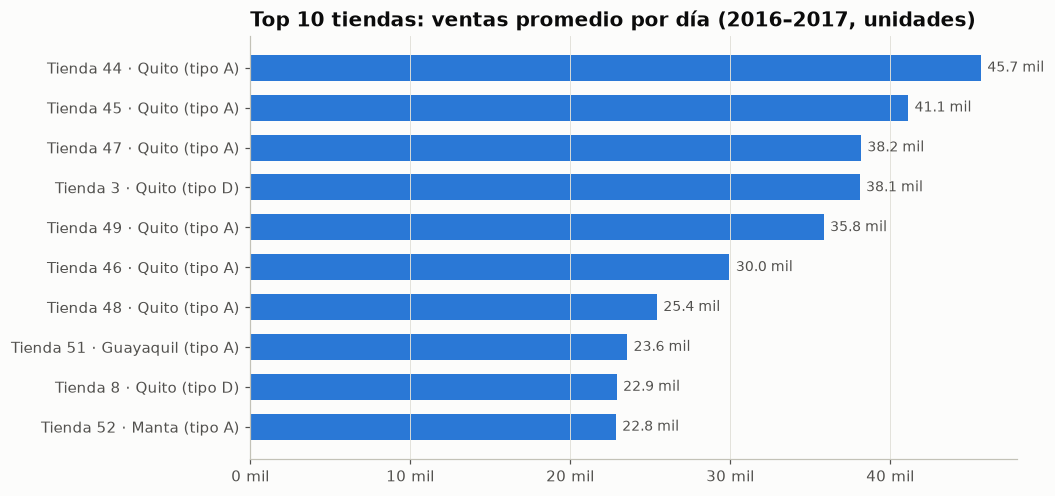

In [13]:
top_tiendas = tiendas.head(10).iloc[::-1]
etiquetas = [f"Tienda {n} · {c} (tipo {t})" for n, c, t in
             zip(top_tiendas["store_nbr"], top_tiendas["city"], top_tiendas["type"])]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiquetas, top_tiendas["ventas_por_dia"], color=AZUL, height=0.65)
for y, v in enumerate(top_tiendas["ventas_por_dia"]):
    ax.text(v + 400, y, f"{v/1e3:,.1f} mil", va="center", fontsize=9, color=TINTA_2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(en_miles))
ax.set_title("Top 10 tiendas: ventas promedio por día (2016–2017, unidades)")
ax.grid(axis="y", visible=False)
guardar(fig, "p3_top_tiendas")
plt.show()

### Paso 3.2 · Por tipo de tienda

In [14]:
por_tipo = tiendas.groupby("type").agg(tiendas=("store_nbr", "count"),
                                        ventas_por_dia_promedio=("ventas_por_dia", "mean")) \
                  .sort_values("ventas_por_dia_promedio", ascending=False)
por_tipo

,tiendas,ventas_por_dia_promedio
type,,
A,9,"31,461.68"
D,18,"14,962.28"
B,8,"14,689.76"
E,4,"12,690.09"
C,15,"8,143.19"


Las tiendas **tipo A** venden en promedio el doble que las B, D y E, y más del triple que las C.
Probablemente A son hipermercados grandes y C tiendas pequeñas (Kaggle no lo documenta, es una inferencia).

### Paso 3.3 · Por ciudad

Aquí hay dos formas de mirar y cuentan historias distintas:

- **Ventas totales de la ciudad:** ¿dónde está el negocio? (favorece a ciudades con muchas tiendas)
- **Ventas promedio por tienda:** ¿qué tan productiva es cada tienda en esa ciudad?

In [15]:
ciudades = tiendas.groupby("city").agg(tiendas=("store_nbr", "count"),
                                        ventas_por_dia_total=("ventas_por_dia", "sum"),
                                        ventas_por_dia_por_tienda=("ventas_por_dia", "mean"))
ciudades["participacion_%"] = ciudades["ventas_por_dia_total"] / ciudades["ventas_por_dia_total"].sum() * 100
ciudades = ciudades.sort_values("ventas_por_dia_total", ascending=False)
ciudades.head(10)

,tiendas,ventas_por_dia_total,ventas_por_dia_por_tienda,participacion_%
city,,,,
Quito,18,"423,688.39","23,538.24",50.27
Guayaquil,8,"93,840.64","11,730.08",11.13
Cuenca,3,"42,127.94","14,042.65",5.00
Manta,2,"35,224.82","17,612.41",4.18
Ambato,2,"28,808.59","14,404.30",3.42
Santo Domingo,3,"28,635.08","9,545.03",3.40
Machala,2,"26,474.41","13,237.21",3.14
Cayambe,1,"19,929.27","19,929.27",2.36
Daule,1,"14,862.30","14,862.30",1.76


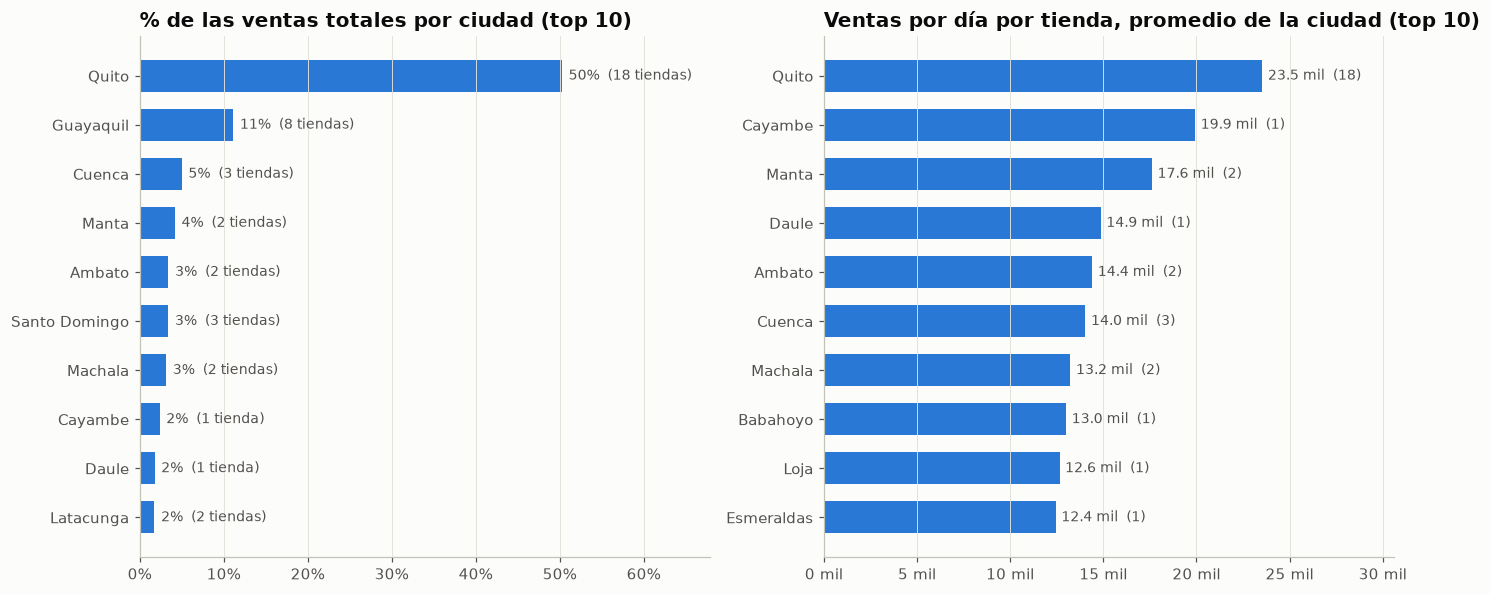

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

c1 = ciudades.head(10).iloc[::-1]
ax1.barh(c1.index, c1["participacion_%"], color=AZUL, height=0.65)
for y, (v, n) in enumerate(zip(c1["participacion_%"], c1["tiendas"])):
    ax1.text(v + 0.8, y, f"{v:.0f}%  ({n} {'tienda' if n == 1 else 'tiendas'})", va="center", fontsize=9, color=TINTA_2)
ax1.set_title("% de las ventas totales por ciudad (top 10)")
ax1.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax1.set_xlim(0, c1["participacion_%"].max() * 1.35)
ax1.grid(axis="y", visible=False)

c2 = ciudades.sort_values("ventas_por_dia_por_tienda").tail(10)
ax2.barh(c2.index, c2["ventas_por_dia_por_tienda"], color=AZUL, height=0.65)
for y, (v, n) in enumerate(zip(c2["ventas_por_dia_por_tienda"], c2["tiendas"])):
    ax2.text(v + 300, y, f"{v/1e3:,.1f} mil  ({n})", va="center", fontsize=9, color=TINTA_2)
ax2.set_title("Ventas por día por tienda, promedio de la ciudad (top 10)")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(en_miles))
ax2.set_xlim(0, c2["ventas_por_dia_por_tienda"].max() * 1.3)
ax2.grid(axis="y", visible=False)

fig.tight_layout()
guardar(fig, "p3_ciudades")
plt.show()

### ✅ Respuesta a la pregunta 3

- **Quito domina:** con 18 de las 54 tiendas (un tercio) concentra el **50% de las ventas**. Quito + Guayaquil
  suman el 61%.
- **Las 7 tiendas que más venden están en Quito** (6 son tipo A). La número 1, la tienda 44, vende ~45.700
  unidades por día.
- **Guayaquil** es la segunda ciudad en ventas totales, pero sus tiendas venden **la mitad que las de Quito**
  (11.700 vs. 23.500 unidades por día y tienda).
- El **tipo de tienda** explica mucho: las tipo **A** venden ~31.500 unidades por día, casi **4 veces** más que
  las tipo **C** (~8.100).
- **Cayambe**, con una sola tienda (tipo B), es la segunda ciudad más productiva por tienda. La tienda 52 de
  Manta abrió en abril de 2017 y ya está entre las 10 que más venden: vale la pena seguirla de cerca.

---
# Pregunta 4 · ¿Las promociones aumentan las ventas?

### Paso 4.1 · Cuidado con la correlación

Lo fácil sería decir: "los días con más promociones se vende más". Pero hay un problema:
**las familias que más venden también son las que tienen más productos en promoción** (`GROCERY I` tiene cientos
de productos, `BOOKS` casi ninguno). Si comparamos sin cuidado, estaríamos comparando familias distintas.

**Solución:** comparar la **misma tienda y la misma familia**, en días **con** promoción vs. días **sin** promoción.
Así comparamos "manzanas con manzanas".

Necesitamos el detalle diario (`train`, que ya cargamos en la pregunta 2) y usamos el **periodo confiable**
(desde junio de 2015): en los meses con huecos, una familia podía tener promociones registradas pero ventas en cero,
lo que distorsionaría la comparación.

In [17]:
promo = train[train["date"] >= PERIODO_CONFIABLE].copy()
promo["con_promo"] = promo["onpromotion"] > 0
print(f"Filas con alguna promoción: {promo['con_promo'].mean():.1%}")

Filas con alguna promoción: 34.7%


### Paso 4.2 · Calcular el "efecto promoción" (*lift*)

Para cada combinación tienda + familia calculamos:

$$\text{lift} = \frac{\text{venta promedio en días CON promoción}}{\text{venta promedio en días SIN promoción}}$$

Un lift de 1,5 significa que en días con promoción se vende un 50% más. Luego tomamos la **mediana** de todas las
tiendas para cada familia (la mediana no se deja distorsionar por casos extremos).

In [18]:
promedios = (promo.groupby(["store_nbr", "family", "con_promo"])["sales"].mean()
             .unstack()
             .rename(columns={False: "sin_promo", True: "con_promo"})
             .dropna())
promedios = promedios[promedios["sin_promo"] > 0]   # evitar dividir por cero
promedios["lift"] = promedios["con_promo"] / promedios["sin_promo"]

print(f"Lift mediano (todas las tiendas y familias): {promedios['lift'].median():.2f}")
print(f"% de combinaciones tienda-familia donde la promo vende más: {(promedios['lift'] > 1).mean():.0%}")

Lift mediano (todas las tiendas y familias): 1.24
% de combinaciones tienda-familia donde la promo vende más: 91%


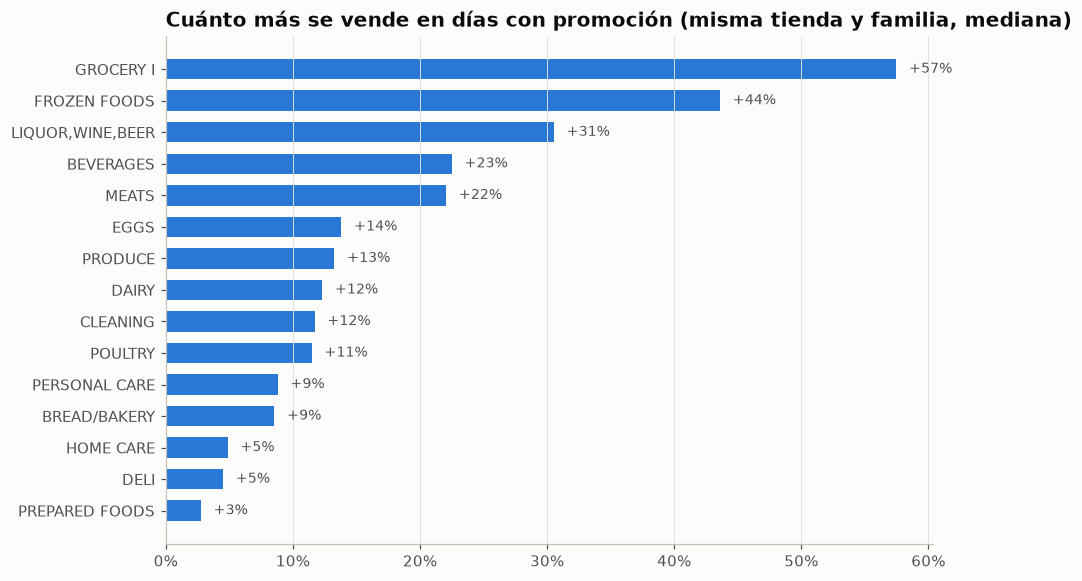

In [19]:
lift_familia = promedios.groupby("family")["lift"].median()
lift_familia = lift_familia[lift_familia.index.isin(relevantes)].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(lift_familia.index, (lift_familia.values - 1) * 100, color=AZUL, height=0.65)
for y, v in enumerate(lift_familia.values):
    ax.text((v - 1) * 100 + 1, y, f"+{(v - 1) * 100:.0f}%", va="center", fontsize=9, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_title("Cuánto más se vende en días con promoción (misma tienda y familia, mediana)")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
guardar(fig, "p4_lift_promociones")
plt.show()

### ✅ Respuesta a la pregunta 4

**Sí, hay una asociación clara, pero más moderada de lo que parece a primera vista.** Comparando la misma tienda
y la misma familia, en los días con promoción se vende típicamente **~24% más** que en días sin promoción, y eso
ocurre en el **91%** de las combinaciones tienda-familia.

- Efecto **mayor** en `GROCERY I` (+57%), `FROZEN FOODS` (+44%) y `LIQUOR,WINE,BEER` (+31%).
- Efecto **casi nulo** en `PREPARED FOODS` (+3%), `DELI` (+5%) y `HOME CARE` (+5%): en estas categorías las
  promociones aportan poco.

> ⚠️ **Correlación no es causalidad.** Este análisis no es un experimento: la empresa podría poner promociones
> justamente en días de alta demanda (quincena, fines de semana, diciembre), y parte del "efecto" vendría de ahí.
> Para medir el efecto real haría falta un experimento (A/B) o controlar por fecha. Aun así, el resultado es una
> buena señal de que las promociones sí mueven las ventas.

---
# Pregunta 5 · ¿Los feriados, el petróleo y el terremoto de 2016 afectaron las ventas?

## 5A · Feriados

### Paso 5A.1 · ¿Contra qué comparamos un feriado?

Un feriado que cae en sábado se vería "alto" solo por ser sábado, y uno de diciembre se vería alto solo por ser diciembre.
Por eso comparamos cada día con un **día normal parecido**: la **mediana de las ventas del mismo día de la semana,
en el mismo mes y año**, usando solo días normales.

$$\text{índice} = \frac{\text{ventas del día}}{\text{mediana de días normales del mismo día de semana, mes y año}}$$

Índice 1,0 = un día normal; 1,3 = 30% más de lo normal; 0,8 = 20% menos.

Usamos las ventas de las **familias completas** para poder incluir los feriados de 2013 a 2015 sin que los huecos
de registro afecten la comparación.

In [20]:
normales = diaria[diaria["tipo_dia"] == "Dia normal"]
referencia = (normales.groupby(["anio", "mes", "dia_semana"])["ventas_familias_completas"].median()
              .rename("venta_referencia").reset_index())

diaria = diaria.merge(referencia, on=["anio", "mes", "dia_semana"], how="left")
diaria["indice"] = diaria["ventas_familias_completas"] / diaria["venta_referencia"]

diaria.groupby("tipo_dia")["indice"].agg(["mean", "count"])

,mean,count
tipo_dia,,
Adicional,1.27,28
Dia normal,1.02,1553
Evento,1.07,53
Feriado,1.08,50


### Paso 5A.2 · ¿Qué feriados mueven más las ventas?

Agrupamos por nombre del feriado. Quitamos sufijos como `-1` o `+1` (ej. `Navidad-1` = 24 de diciembre)
para agrupar los días alrededor del mismo feriado.

In [21]:
especiales = diaria[diaria["tipo_dia"] != "Dia normal"].copy()
especiales["feriado"] = (especiales["descripcion_feriado"]
                         .str.replace(r"[-+]\d+$", "", regex=True)
                         .str.replace("Traslado ", "", regex=False)
                         .str.replace("Puente ", "", regex=False)
                         .str.strip())
especiales.loc[especiales["feriado"].str.startswith("Mundial"), "feriado"] = "Mundial de fútbol 2014"
especiales.loc[especiales["feriado"].str.startswith("Terremoto"), "feriado"] = "Terremoto Manabí"

por_feriado = (especiales.groupby("feriado")["indice"].agg(["mean", "count"])
               .sort_values("mean"))
por_feriado

,mean,count
feriado,,
Primer dia del ano,0.78,10
Dia de la Madre,0.91,9
Primer Grito de Independencia,0.98,5
Black Friday,0.99,3
Viernes Santo,0.99,5
Inauguracion Mundial de futbol Brasil,1.00,1
Mundial de fútbol 2014,1.01,13
Cyber Monday,1.02,3
Carnaval,1.05,10


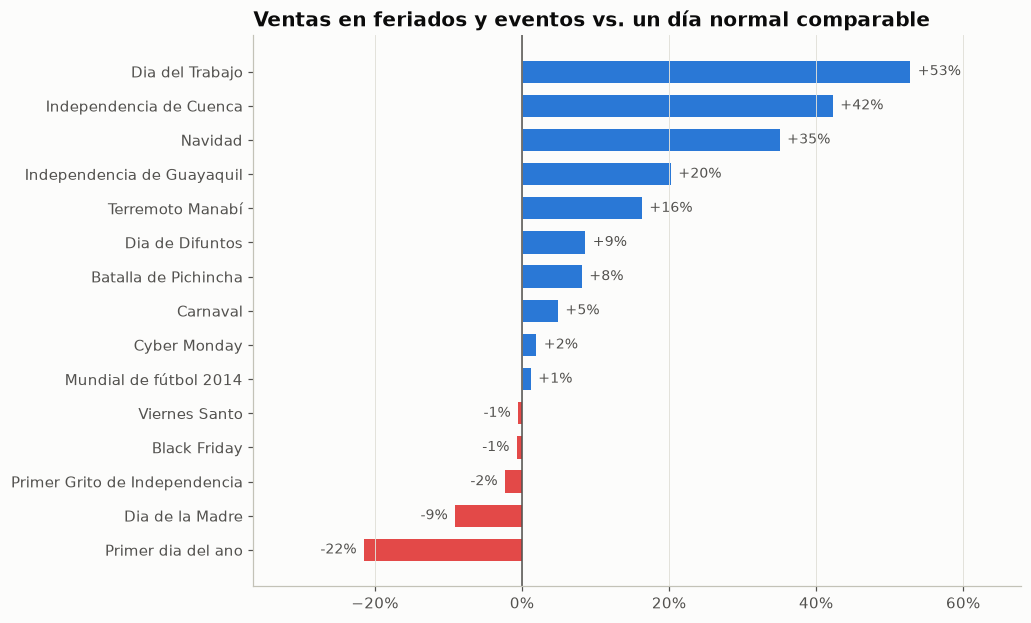

In [22]:
graf = por_feriado[por_feriado["count"] >= 3]["mean"]
cambio = (graf - 1) * 100

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(cambio.index, cambio.values, color=[ROJO if v < 0 else AZUL for v in cambio.values], height=0.65)
for y, v in enumerate(cambio.values):
    ax.text(v + (1 if v >= 0 else -1), y, f"{v:+.0f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_title("Ventas en feriados y eventos vs. un día normal comparable")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(cambio.min() - 15, cambio.max() + 15)
ax.grid(axis="y", visible=False)
guardar(fig, "p5_feriados")
plt.show()

**¿Qué vemos?**

- **Navidad** (del 21 al 26 de diciembre) es el periodo que más sube las ventas: **+35%** sobre un día normal.
- **Día del Trabajo** (+53%) e **Independencia de Cuenca** (+42%) también suben mucho, pero ambos caen a
  inicio de mes (1 de mayo y 3 de noviembre), justo después del pago de sueldos. Parte del efecto puede venir
  de ahí y no del feriado en sí.
- **1 de enero** vende un **22% menos** (muchas tiendas abren menos horas) y el **Día de la Madre** un 9% menos.
- Muchos feriados y eventos **casi no cambian las ventas**: Carnaval (+5%), Mundial 2014 (+1%),
  Viernes Santo (−1%) y Black Friday (−1%).
- Cada feriado aparece solo de 3 a 10 veces en los datos, así que estos números son **orientativos**.

## 5B · Petróleo

### Paso 5B.1 · Mirar las dos series

Ecuador depende del petróleo, y el precio se desplomó a fines de 2014 (de ~100 a ~45 dólares).
Ponemos las dos series **en gráficos separados** con el mismo eje de tiempo (nunca dos ejes Y en un mismo gráfico:
es fácil engañar al lector así).

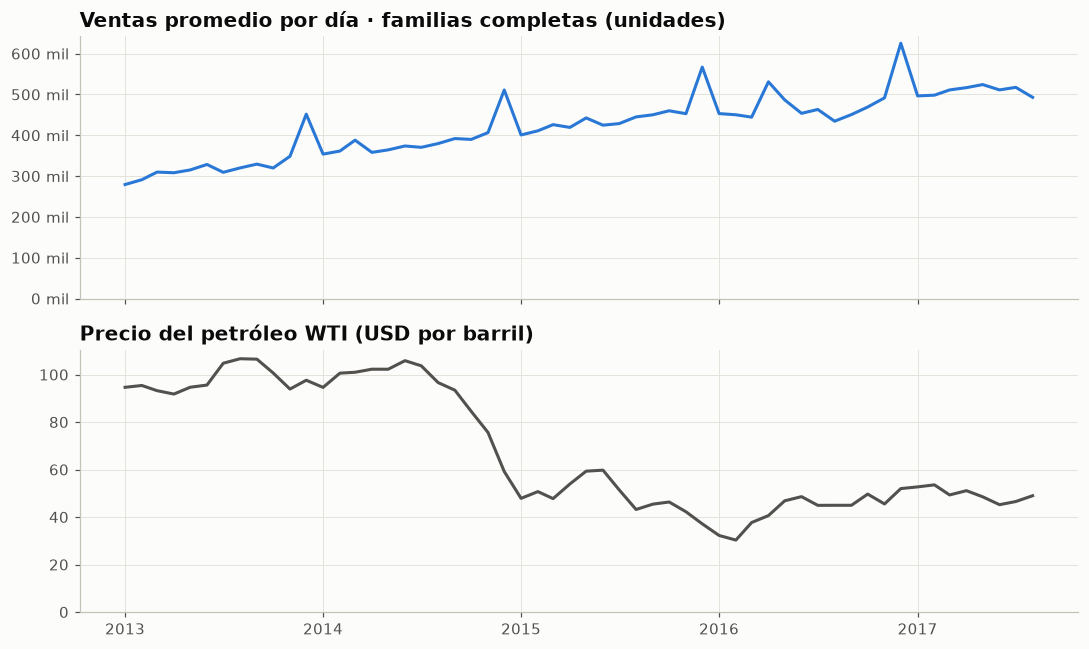

In [23]:
mensual_pais = (diaria.set_index("date")[["ventas_familias_completas", "precio_petroleo"]]
                .resample("MS").mean()
                .rename(columns={"ventas_familias_completas": "ventas"}))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax1.plot(mensual_pais.index, mensual_pais["ventas"], color=AZUL)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(en_miles))
ax1.set_title("Ventas promedio por día · familias completas (unidades)")
ax1.set_ylim(0)
ax2.plot(mensual_pais.index, mensual_pais["precio_petroleo"], color=TINTA_2)
ax2.set_title("Precio del petróleo WTI (USD por barril)")
ax2.set_ylim(0)
fig.tight_layout()
guardar(fig, "p5_petroleo")
plt.show()

### Paso 5B.2 · La trampa de la correlación

Si calculamos la correlación directamente, sale **fuertemente negativa**. ¿Significa que cuando el petróleo baja
la gente compra más? **No necesariamente.** Las ventas suben todo el tiempo (tendencia) y el petróleo bajó en ese
periodo: dos series con tendencia casi siempre salen correlacionadas, aunque no tengan nada que ver
(esto se llama **correlación espuria**).

La forma correcta es correlacionar los **cambios**: si un mes el petróleo cae, ¿ese mes cambian las ventas?

In [24]:
corr_niveles = mensual_pais["ventas"].corr(mensual_pais["precio_petroleo"])
cambios = mensual_pais.pct_change().dropna()
corr_cambios = cambios["ventas"].corr(cambios["precio_petroleo"])
cambios_anuales = mensual_pais.pct_change(12).dropna()
corr_anual = cambios_anuales["ventas"].corr(cambios_anuales["precio_petroleo"])

print(f"Correlación de los niveles (engañosa):          {corr_niveles:+.2f}")
print(f"Correlación de cambios mes a mes:               {corr_cambios:+.2f}")
print(f"Correlación de cambios vs. mismo mes año ant.:  {corr_anual:+.2f}")

Correlación de los niveles (engañosa):          -0.79
Correlación de cambios mes a mes:               +0.04
Correlación de cambios vs. mismo mes año ant.:  -0.20


**¿Qué vemos?** Al quitar la tendencia, la correlación prácticamente **desaparece**. Con estos datos **no hay
evidencia de un efecto directo y rápido** del precio del petróleo sobre las ventas. Las ventas siguieron creciendo
incluso después de la caída del precio. (Un efecto indirecto de largo plazo sobre la economía es posible, pero no se
puede demostrar con este análisis.)

## 5C · Terremoto del 16 de abril de 2016

El terremoto de magnitud 7,8 golpeó la provincia de Manabí un sábado por la noche. Hubo una gran ola de
donaciones de agua, alimentos y artículos de primera necesidad. Miramos el índice diario (ventas vs. día normal
comparable) entre marzo y mayo de 2016.

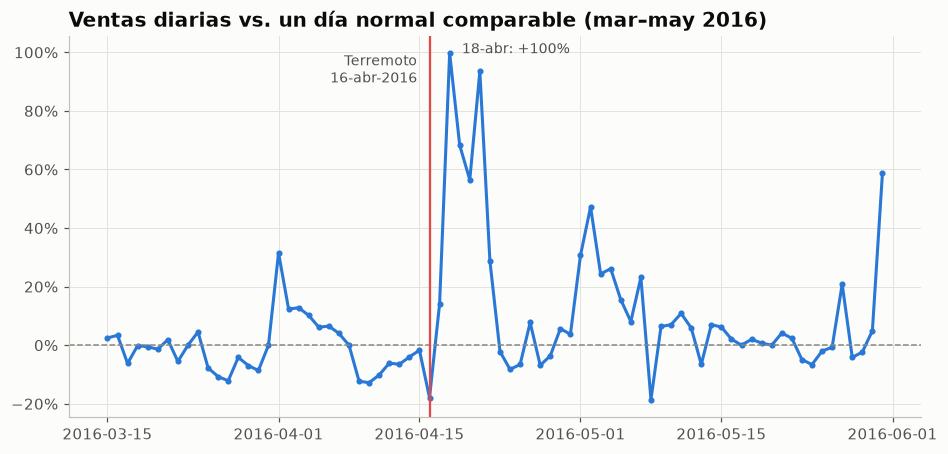

In [25]:
ventana = diaria[(diaria["date"] >= "2016-03-15") & (diaria["date"] <= "2016-05-31")]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(ventana["date"], (ventana["indice"] - 1) * 100, color=AZUL, marker="o", markersize=3)
ax.axhline(0, color=GRIS, linewidth=1, linestyle="--")
ax.axvline(pd.Timestamp("2016-04-16"), color=ROJO, linewidth=1.5)
ax.annotate("Terremoto\n16-abr-2016", (pd.Timestamp("2016-04-16"), (ventana["indice"].max() - 1) * 90), xytext=(-8, 0),
            textcoords="offset points", ha="right", fontsize=9, color=TINTA_2)
pico = ventana.loc[ventana["indice"].idxmax()]
ax.annotate(f"{pico['date'].day}-abr: +{(pico['indice'] - 1) * 100:.0f}%", (pico["date"], (pico["indice"] - 1) * 100),
            xytext=(8, 0), textcoords="offset points", fontsize=9, color=TINTA_2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("Ventas diarias vs. un día normal comparable (mar–may 2016)")
guardar(fig, "p5_terremoto")
plt.show()

¿Qué productos se dispararon? Comparamos la semana después del terremoto (17 al 23 de abril) con las 3 semanas
anteriores (promedio semanal):

In [26]:
t = train[(train["date"] >= "2016-03-27") & (train["date"] <= "2016-04-23")]
antes = t[t["date"] <= "2016-04-16"].groupby("family")["sales"].sum() / 3   # 3 semanas -> promedio semanal
despues = t[t["date"] >= "2016-04-17"].groupby("family")["sales"].sum()

terremoto = pd.DataFrame({"semana_promedio_antes": antes, "semana_despues": despues})
terremoto["cambio_%"] = (terremoto["semana_despues"] / terremoto["semana_promedio_antes"] - 1) * 100
terremoto["unidades_extra"] = terremoto["semana_despues"] - terremoto["semana_promedio_antes"]
terremoto.sort_values("unidades_extra", ascending=False).head(8)

,semana_promedio_antes,semana_despues,cambio_%,unidades_extra
family,,,,
GROCERY I,"1,592,448.39","2,901,869.09",82.23,"1,309,420.70"
BEVERAGES,"1,156,461.33","1,800,888.00",55.72,"644,426.67"
CLEANING,"426,821.00","549,856.00",28.83,"123,035.00"
PERSONAL CARE,"117,006.00","218,120.00",86.42,"101,114.00"
HOME CARE,"107,365.67","180,010.00",67.66,"72,644.33"
BREAD/BAKERY,"189,998.83","216,595.24",14.00,"26,596.40"
DAIRY,"326,661.00","338,064.00",3.49,"11,403.00"
POULTRY,"147,142.80","154,130.09",4.75,"6,987.29"


### ✅ Respuesta a la pregunta 5

- **Feriados:** sí afectan, pero **no todos igual ni en la misma dirección**. La época navideña sube las ventas
  (+35%), el 1 de enero las baja (−22%) y muchos feriados no tienen un efecto visible. Para medirlo bien hay que
  tratar correctamente los **feriados trasladados** (el día con `transferred=True` fue un día normal) y comparar
  contra un día normal del mismo día de la semana y mes.
- **Petróleo:** la correlación de −0,79 es **espuria** (se debe a las tendencias). Al comparar los cambios mes a mes,
  la correlación es prácticamente cero (+0,04): **no hay evidencia de un efecto directo** en el corto plazo.
- **Terremoto:** provocó un **pico fuerte y corto**. El lunes 18 de abril se vendió **el doble** que un día
  normal, y la semana del 17 al 23 de abril vendió un 43% más que el promedio de las 3 semanas anteriores.
  Subieron sobre todo abarrotes (+82%), cuidado personal (+86%), cuidado del hogar (+68%) y bebidas (+56%),
  lo que coincide con la compra de artículos de primera necesidad para donaciones. **En una semana**
  (desde el 23 de abril) las ventas volvieron a la normalidad.

---
## Resumen final

| Pregunta | Respuesta corta |
|---|---|
| 1. Evolución y estacionalidad | Crecimiento anual que se desacelera (+20% → +9%); pico en diciembre, fines de semana y días de pago. |
| 2. Familias | `GROCERY I`, `BEVERAGES` y `PRODUCE` = 2/3 de las ventas. Crecen EGGS, BEVERAGES y DAIRY (~+10%); caen PREPARED FOODS y FROZEN FOODS. |
| 3. Tiendas y ciudades | Quito = 50% de las ventas con 1/3 de las tiendas; las tiendas tipo A venden ~4 veces más que las C. |
| 4. Promociones | Asociadas a ~24% más ventas en la misma tienda y familia (no prueba causalidad). |
| 5. Feriados, petróleo, terremoto | Navidad +35%, 1-ene −22%; petróleo sin efecto visible; terremoto = pico de una semana (hasta +100%). |